# 🎓 Encontro 4 — Modelos de Visão Computacional para Edição de Imagens

## Background removal, content-aware fill e edição de pessoas

Vamos trabalhar do início ao fim em cima de **uma única fotografia real** (`imgs/beach.jpg`). A partir dela, vamos:

1. **Segmentar** o cachorro do restante da cena;
2. **Remover** o cachorro da foto, preenchendo o buraco de forma inteligente (*content-aware fill* / inpainting);
3. **Remover as pessoas** da cena e discutir por que essa tarefa é mais difícil;
4. **Reinserir** o cachorro em outro lugar da praia, comparando duas técnicas de composição.

A ideia é sair da aula entendendo, na prática, o que acontece "por trás" de ferramentas como o remove.bg, o Content-Aware Fill do Photoshop e o "object removal" de aplicativos de celular — e também entender **onde a abordagem clássica (a que vamos implementar) para de funcionar**, e por que a indústria migrou para modelos profundos (SAM, LaMa, modelos de difusão) nessas tarefas.

### Objetivos de aprendizagem

Ao final deste encontro, você deve ser capaz de:

- explicar a imagem como tensor $H \times W \times 3$ e a máscara como um tensor binário sobre o mesmo domínio;
- descrever o funcionamento do **GrabCut** (segmentação interativa por corte de grafo) e reconhecer suas limitações;
- comparar os algoritmos de inpainting **Telea** e **Navier-Stokes** e escolher entre eles;
- **executar e criticar** um pipeline de remoção de objetos/pessoas, incluindo seus artefatos;
- comparar a composição por **alpha blending** com a composição por **gradiente (Poisson blending)**;
- posicionar cada técnica clássica em relação ao estado da arte atual em modelos generativos.



In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['figure.dpi'] = 120


def carregar_imagem_rgb(nome_arquivo):
    """Localiza a imagem em imgs/ (raiz do projeto ou pasta do notebook) e devolve em RGB."""
    candidatos = [
        Path.cwd() / 'imgs' / nome_arquivo,
        Path.cwd().parent / 'imgs' / nome_arquivo,
        Path('/home/ryan/repositories/P2026D/imgs') / nome_arquivo,
    ]
    caminho = next((p for p in candidatos if p.exists()), None)
    if caminho is None:
        raise FileNotFoundError(f"Imagem não encontrada: {nome_arquivo}")
    imagem = cv2.imread(str(caminho))
    if imagem is None:
        raise FileNotFoundError(f"Não foi possível carregar a imagem em {caminho}")
    return cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)


def mostrar_imagem(img, titulo='Imagem', cmap=None):
    _, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img, cmap=cmap)
    ax.set_title(titulo, fontsize=12)
    ax.axis('off')
    plt.show()


def mostrar_lado_a_lado(imagens, titulos, figsize=(16, 5), cmaps=None):
    _, axes = plt.subplots(1, len(imagens), figsize=figsize)
    if len(imagens) == 1:
        axes = [axes]
    cmaps = cmaps or [None] * len(imagens)
    for ax, img, titulo, cmap in zip(axes, imagens, titulos, cmaps):
        ax.imshow(img, cmap=cmap)
        ax.set_title(titulo, fontsize=11)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def mostrar_mascara_sobreposta(img, mask, titulo='Máscara sobre a imagem', cor=(255, 0, 60), alpha=0.45):
    """Desenha uma máscara binária como uma camada colorida translúcida sobre a imagem original."""
    overlay = img.copy().astype(np.float32)
    cor_arr = np.array(cor, dtype=np.float32)
    binaria = mask > 0
    overlay[binaria] = (1 - alpha) * overlay[binaria] + alpha * cor_arr
    mostrar_imagem(overlay.astype(np.uint8), titulo)


def desenhar_caixas(img, caixas, cor=(255, 0, 60), espessura=3):
    """caixas: dict {rotulo: (x, y, largura, altura)}. Devolve uma cópia anotada da imagem."""
    anotada = img.copy()
    for rotulo, (x, y, w, h) in caixas.items():
        cv2.rectangle(anotada, (x, y), (x + w, y + h), cor, espessura)
        cv2.putText(anotada, rotulo, (x, max(y - 10, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, cor, 2, cv2.LINE_AA)
    return anotada


def mascara_com_feather(mask_uint8, sigma=9):
    """Suaviza as bordas de uma máscara binária (0/255) para permitir composição sem costura visível."""
    suavizada = cv2.GaussianBlur(mask_uint8, (0, 0), sigmaX=sigma)
    return (suavizada.astype(np.float32) / 255.0)[:, :, None]



ModuleNotFoundError: No module named 'cv2'

### Imagem de trabalho: a praia

Vamos usar a mesma fotografia (`imgs/beach.jpg`) do início ao fim da aula. Ela tem três elementos que nos interessam:

- a **mãe segurando a criança**, à esquerda, contra um fundo relativamente uniforme (areia clara e, um pouco acima, o horizonte do mar);
- o **cachorro**, à direita, isolado sobre a areia — um caso "fácil" de segmentação;
- o **horizonte do mar**, que vira um problema quando uma máscara de remoção precisa atravessá-lo (veremos isso na Seção 4).

As caixas abaixo são as regiões aproximadas que vamos usar como ponto de partida em várias seções. Guarde os valores de `rect_cachorro` e `rect_pessoas`: eles reaparecem depois.


shape: (800, 1200, 3) | dtype: uint8


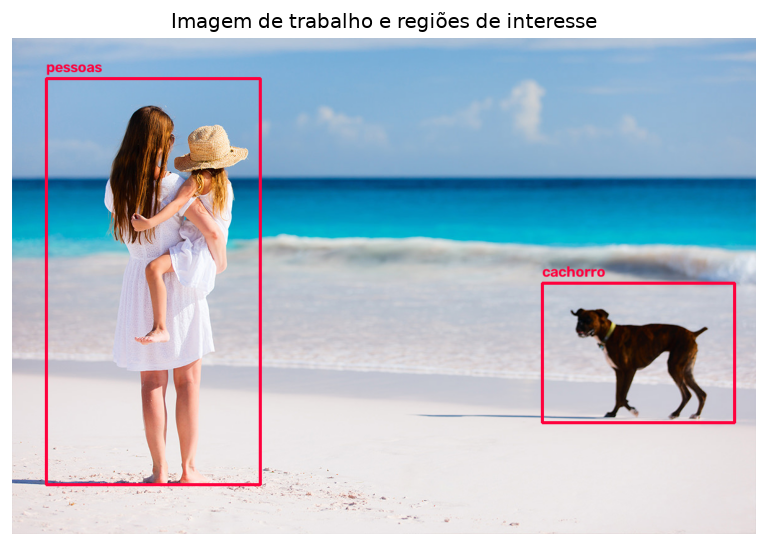

In [ ]:
imagem_base = carregar_imagem_rgb('beach.jpg')
print('shape:', imagem_base.shape, '| dtype:', imagem_base.dtype)

rect_cachorro = (855, 395, 310, 225)  # x, y, largura, altura
rect_pessoas = (55, 65, 345, 655)

caixas = {'cachorro': rect_cachorro, 'pessoas': rect_pessoas}
mostrar_imagem(desenhar_caixas(imagem_base, caixas), 'Imagem de trabalho e regiões de interesse')


## 1. Fundamentos matemáticos

Do ponto de vista matemático, uma imagem digital é uma função discreta
$I : \Omega \rightarrow \mathbb{R}^{3}$, onde $\Omega = \{1,\dots,H\} \times \{1,\dots,W\}$
representa os pixels e cada posição $(x, y)$ contém um vetor de canais RGB.

Em outras palavras, a imagem é uma grade de pontos, cada ponto guarda um valor numérico. Em tons de cinza, ela vira uma matriz 2D; em RGB, vira um tensor 3D:

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

A ideia da segmentação é encontrar uma máscara binária — um tensor com o **mesmo domínio espacial** da imagem, mas apenas 1 canal —
$M(x,y) \in \{0,1\}$, onde $M=1$ indica o objeto principal e $M=0$ indica o fundo.

Quando removemos um objeto, queremos preencher a região faltante usando informação visual dos vizinhos. Isso é o **inpainting**. Uma formulação clássica é:

$$
\min_{J} \sum_{(x,y)\in \Omega_{\text{faltante}}} \|J(x,y) - I(x,y)\|^2 + \lambda \sum_{(x,y)\in \Omega} \|\nabla J(x,y)\|^2
$$

Em palavras simples: queremos que o preenchimento fique coerente com o contexto visual e, ao mesmo tempo, permaneça suave e plausível.

Para inserir um objeto em uma cena, usamos composição por transparência:

$$
I_{\text{final}} = \alpha \cdot I_{\text{objeto}} + (1 - \alpha) \cdot I_{\text{fundo}}
$$

onde $\alpha$ é a máscara de transparência. Esse é o coração das ferramentas de edição visual moderna.

Todas as quatro tarefas da aula de hoje seguem, no fundo, essa mesma receita em três passos: **(1)** descrever uma região de interesse com uma máscara $M$, **(2)** resolver um problema de otimização sobre essa região (energia de segmentação, energia de inpainting ou energia de composição) e **(3)** compor o resultado de volta na imagem original.


Altura (H): 800 px | Largura (W): 1200 px | Canais: 3


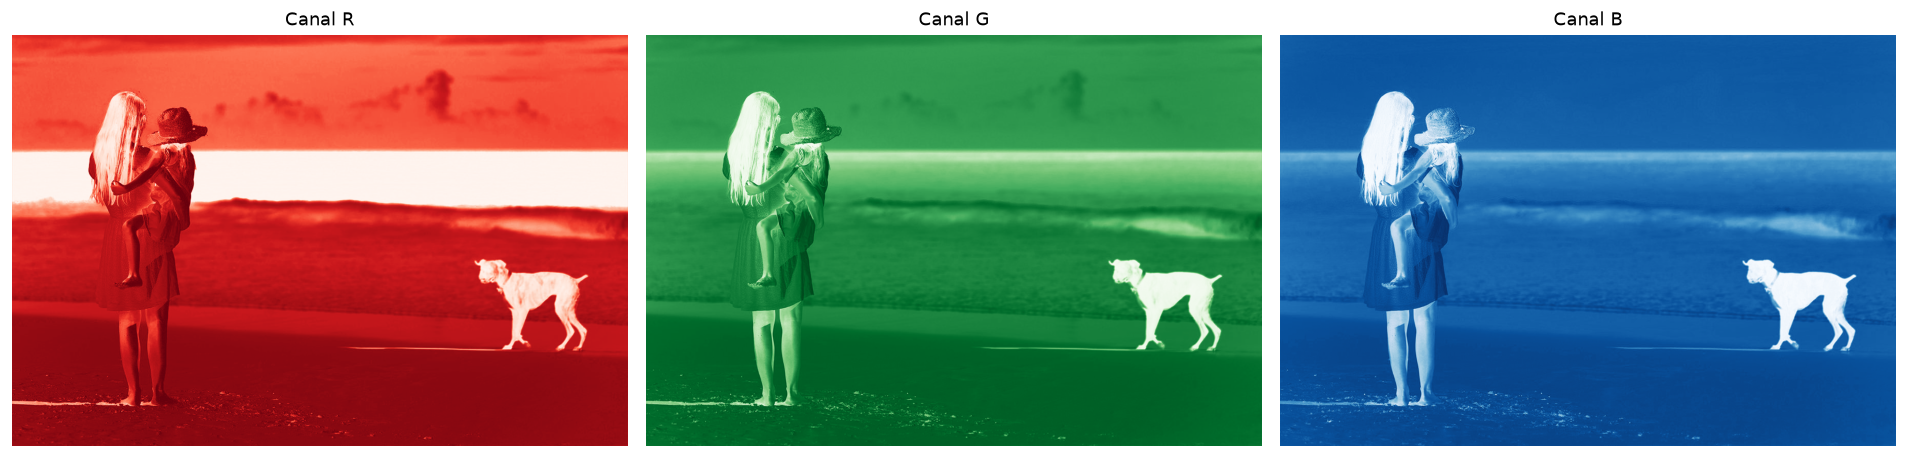

Proporção de pixels muito claros na imagem: 0.424


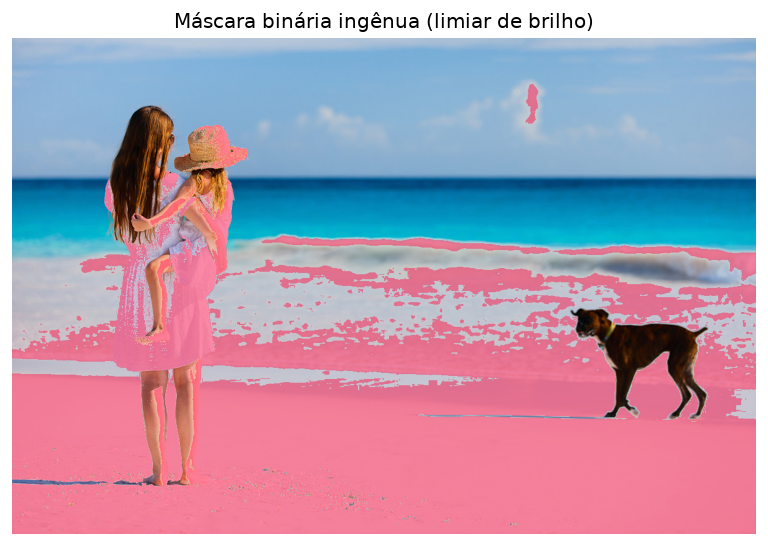

In [ ]:
altura, largura, canais = imagem_base.shape
print(f'Altura (H): {altura} px | Largura (W): {largura} px | Canais: {canais}')

canal_r, canal_g, canal_b = imagem_base[:, :, 0], imagem_base[:, :, 1], imagem_base[:, :, 2]
mostrar_lado_a_lado(
    [canal_r, canal_g, canal_b],
    ['Canal R', 'Canal G', 'Canal B'],
    cmaps=['Reds', 'Greens', 'Blues']
)

# uma máscara "artesanal": pixels muito claros (areia/céu) vs. o resto
cinza = cv2.cvtColor(imagem_base, cv2.COLOR_RGB2GRAY)
mascara_clara = (cinza > 200).astype(np.uint8)
print('Proporção de pixels muito claros na imagem:', round(mascara_clara.mean(), 3))
mostrar_mascara_sobreposta(imagem_base, mascara_clara * 255, 'Máscara binária ingênua (limiar de brilho)')


## 2. Background removal: separando objeto e fundo

O Photoshop chama de "Selecionar assunto"; o remove.bg faz disso um produto inteiro. A tarefa é: dado um retângulo aproximado ao redor de um objeto, encontrar automaticamente **qual pixel pertence ao objeto** e qual pertence ao fundo.

### GrabCut em poucas palavras

O **GrabCut** (Rother, Kolmogorov & Blake, 2004) modela o problema como a minimização de uma energia sobre a máscara $M$:

$$
E(M) = \underbrace{\sum_{p} D(p, M_p)}_{\text{quão bem cada pixel se ajusta ao modelo de cor}} \; + \; \underbrace{\sum_{(p,q) \text{ vizinhos}} V(p, q, M_p, M_q)}_{\text{penaliza fronteiras "picotadas"}}
$$

Na prática, o algoritmo:

1. usa o retângulo inicial para separar grosseiramente "dentro" (possível objeto) de "fora" (certamente fundo);
2. ajusta dois **Gaussian Mixture Models (GMM)** de cor — um para o objeto, um para o fundo;
3. constrói um grafo em que cada pixel é um nó e calcula o **corte mínimo (min-cut / max-flow)** que melhor separa objeto e fundo;
4. repete os passos 2–3 por algumas iterações, refinando a máscara a cada rodada.

O resultado é uma máscara com 4 valores possíveis (fundo certo, fundo provável, objeto certo, objeto provável), que colapsamos em uma máscara binária.

**Limitação importante:** o GrabCut raciocina em termos de *estatística de cor local*, não de "entendimento" do objeto. Quando o objeto e o fundo têm cores parecidas (por exemplo, um vestido claro sobre areia clara), o corte de grafo pode "vazar". Vamos ver um exemplo real disso ainda nesta seção.


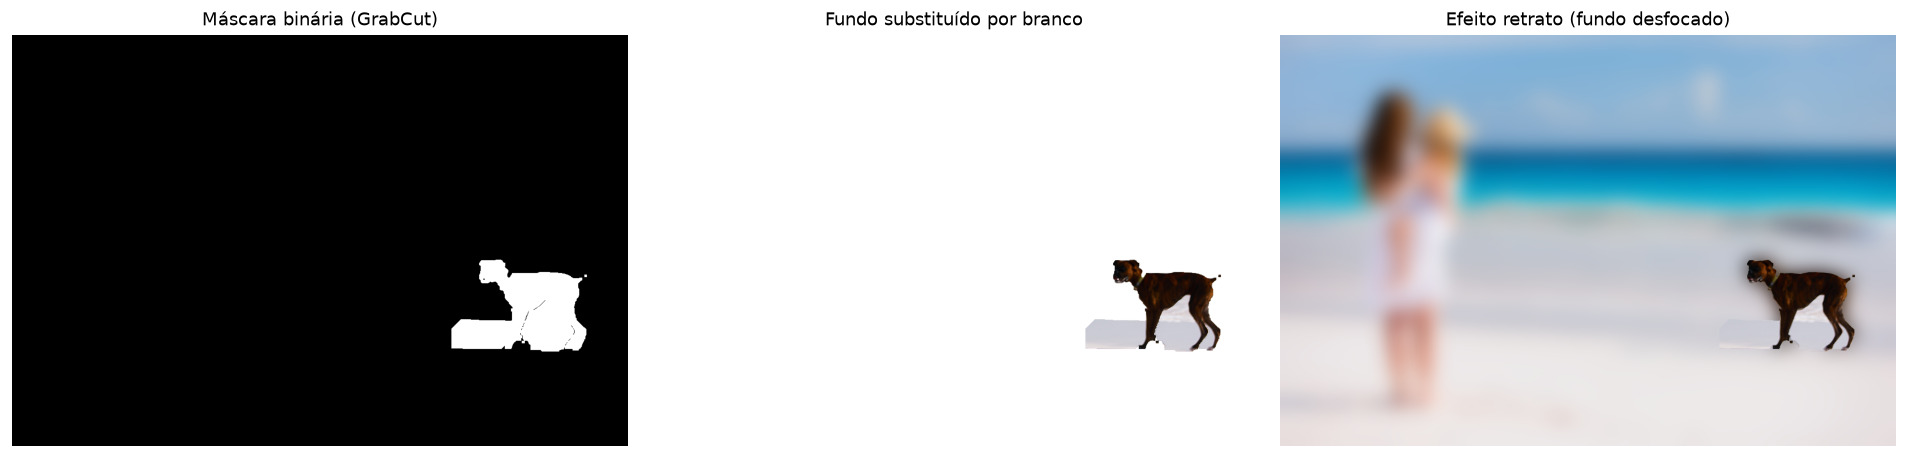

In [ ]:
def segmentar_grabcut(imagem, rect_principal, rect_excluir=None, iteracoes=10):
    """Roda o GrabCut com refinamento e devolve uma máscara binária limpa (1 = objeto, 0 = fundo)."""
    mascara = np.zeros(imagem.shape[:2], dtype=np.uint8)
    modelo_fundo = np.zeros((1, 65), np.float64)
    modelo_objeto = np.zeros((1, 65), np.float64)
    
    # 1ª Passada: Inicialização pelo Retângulo Principal
    cv2.grabCut(imagem, mascara, rect_principal, modelo_fundo, modelo_objeto, iteracoes, cv2.GC_INIT_WITH_RECT)
    
    # 2ª Passada: Forçando uma área específica para o fundo
    if rect_excluir is not None:
        # Desempacota as coordenadas do retângulo que deve sumir (x, y, largura, altura)
        x_ex, y_ex, w_ex, h_ex = rect_excluir
        
        # Converte x, y, w, h para os índices de fatia da matriz
        y_inicio, y_fim = y_ex, y_ex + h_ex
        x_inicio, x_fim = x_ex, x_ex + w_ex
        
        # Força a área da matriz a ser fundo absoluto (0)
        mascara[y_inicio:y_fim, x_inicio:x_fim] = 0
        
        # Roda a 2ª passada com a máscara modificada
        cv2.grabCut(imagem, mascara, None, modelo_fundo, modelo_objeto, iteracoes, cv2.GC_INIT_WITH_MASK)
    
    # Extração da máscara binária (0 e 2 viram 0; 1 e 3 viram 1)
    mascara_binaria = np.where((mascara == 2) | (mascara == 0), 0, 1).astype('uint8')
    
    # Pós-processamento: Limpeza Morfológica
    kernel = np.ones((5, 5), np.uint8)
    mascara_limpa = cv2.morphologyEx(mascara_binaria, cv2.MORPH_OPEN, kernel)
    
    return mascara_limpa

mask_cachorro = segmentar_grabcut(imagem_base, rect_cachorro, rect_excluir=rect_pessoas)


fundo_branco = np.full_like(imagem_base, 255)
cachorro_fundo_branco = imagem_base * mask_cachorro[:, :, None] + fundo_branco * (1 - mask_cachorro[:, :, None])

fundo_desfocado = cv2.GaussianBlur(imagem_base, (0, 0), sigmaX=18)
efeito_retrato = (
    imagem_base * mask_cachorro[:, :, None] + fundo_desfocado * (1 - mask_cachorro[:, :, None])
).astype(np.uint8)

mostrar_lado_a_lado(
    [mask_cachorro * 255, cachorro_fundo_branco, efeito_retrato],
    ['Máscara binária (GrabCut)', 'Fundo substituído por branco', 'Efeito retrato (fundo desfocado)'],
    cmaps=['gray', None, None]
)

### Exercício rápido: será que funciona para qualquer objeto?

Antes de seguir, vale testar o mesmo pipeline na região das pessoas (`rect_pessoas`). É tentador achar que basta trocar o retângulo — vamos conferir.


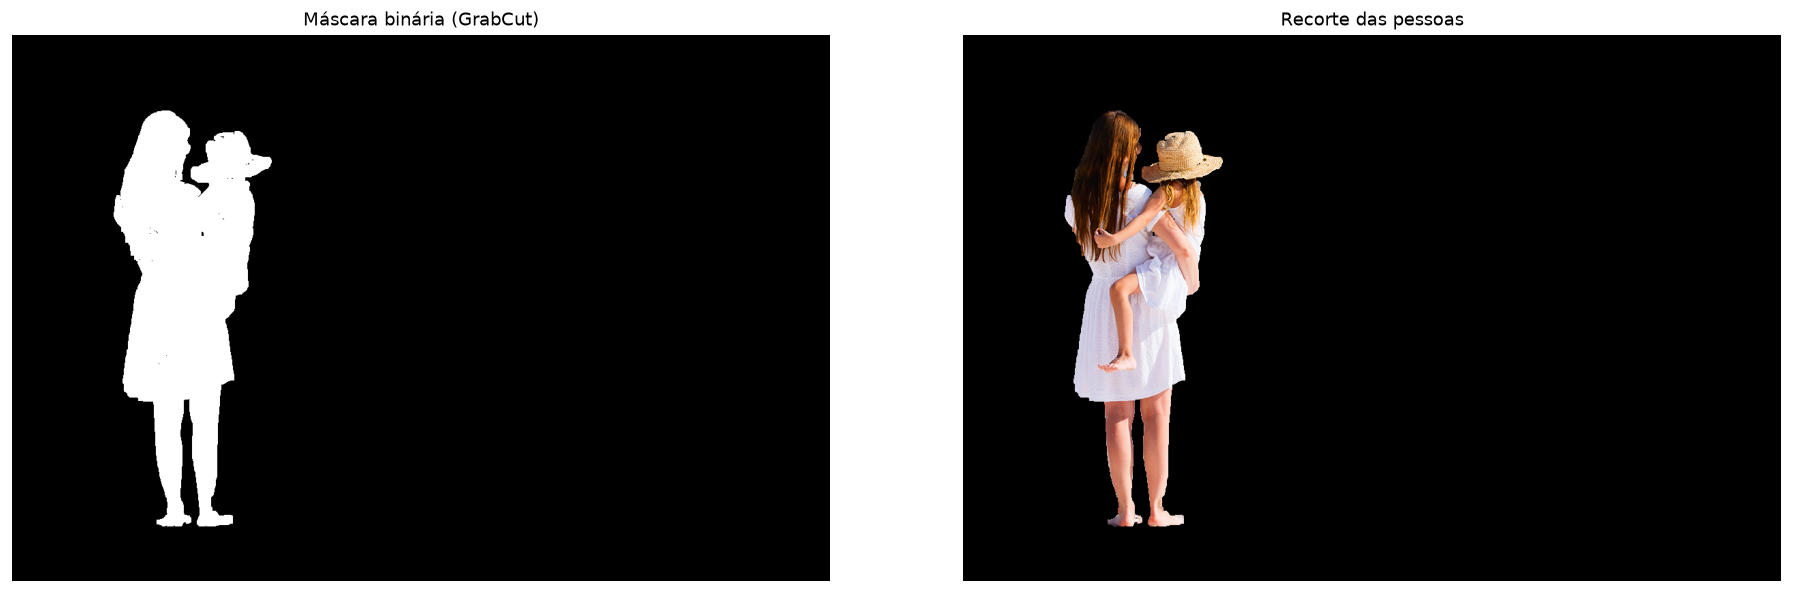

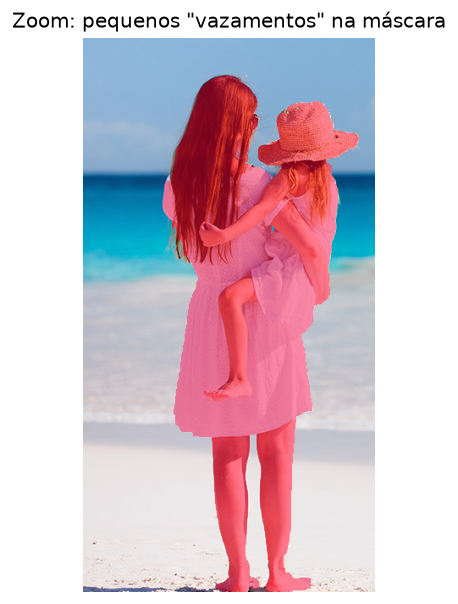

In [ ]:
mask_pessoas = segmentar_grabcut(imagem_base, rect_pessoas, rect_excluir=rect_cachorro)
mostrar_lado_a_lado(
    [mask_pessoas * 255, imagem_base * mask_pessoas[:, :, None]],
    ['Máscara binária (GrabCut)', 'Recorte das pessoas'],
    cmaps=['gray', None]
)

# zoom na região entre o braço e o corpo, onde o céu/mar pode "vazar" pela máscara
x, y, w, h = rect_pessoas
zoom = imagem_base[y:y + h, x:x + w]
zoom_mask = mask_pessoas[y:y + h, x:x + w]
mostrar_mascara_sobreposta(zoom, zoom_mask * 255, 'Zoom: pequenos "vazamentos" na máscara')


Repare no pequeno "vazamento" próximo ao braço/mão: um pedacinho de céu ou mar tem estatística de cor parecida o suficiente com o que o GMM aprendeu como "possível objeto" (pele/roupa clara), então o corte de grafo inclui esse pedaço na máscara.

Correções típicas na prática:
- refinamento manual (o usuário "pinta" a correção — é literalmente assim que o GrabCut do GIMP/Photoshop funciona);
- pós-processamento morfológico (abrir/fechar a máscara para remover pequenos furos e ilhas);
- trocar o método por **segmentação semântica** (redes neurais), que entende "isso é uma pessoa" e não só "isso tem essa cor".


## 3. Content-aware fill: preenchendo o que foi apagado

Agora vamos usar a máscara do cachorro (`mask_cachorro`, calculada na seção anterior) para **apagá-lo da cena** e reconstruir a areia que estava atrás dele — o mesmo tipo de operação por trás do "Content-Aware Fill" do Photoshop ou do "Magic Eraser" do Google Fotos.

### Duas famílias de algoritmos clássicos

O OpenCV implementa dois algoritmos de inpainting, escolhidos pela *flag* de `cv2.inpaint`:

- **`cv2.INPAINT_TELEA`** (Telea, 2004): para cada pixel a preencher, calcula uma média ponderada dos pixels conhecidos próximos, priorizando os que estão na direção normal à borda da região e mais perto dela — uma espécie de *fast marching* que propaga informação de fora para dentro.
- **`cv2.INPAINT_NS`** (Navier-Stokes, Bertalmío et al., 2001): trata a imagem como um fluido e propaga simultaneamente **intensidade e curvatura das isolinhas**, resolvendo uma versão discreta das equações de Navier-Stokes da dinâmica dos fluidos — tende a preservar melhor bordas e estruturas retas.

Formalmente, os dois tentam resolver algo equivalente a

$$
\min_{J} \sum_{(x,y) \in \Omega} \|\nabla J(x,y) - \nabla I(x,y)\|^2 \quad \text{sujeito a} \quad J = I \text{ fora de } \Omega,
$$

isto é: preencher a região que falta ($\Omega$) de forma que o campo de gradientes seja o mais parecido possível com o que existiria em uma continuação natural da imagem.

Um parâmetro comum aos dois métodos é o **raio de inpainting**: quantos pixels ao redor da borda são considerados "vizinhança relevante" a cada passo.


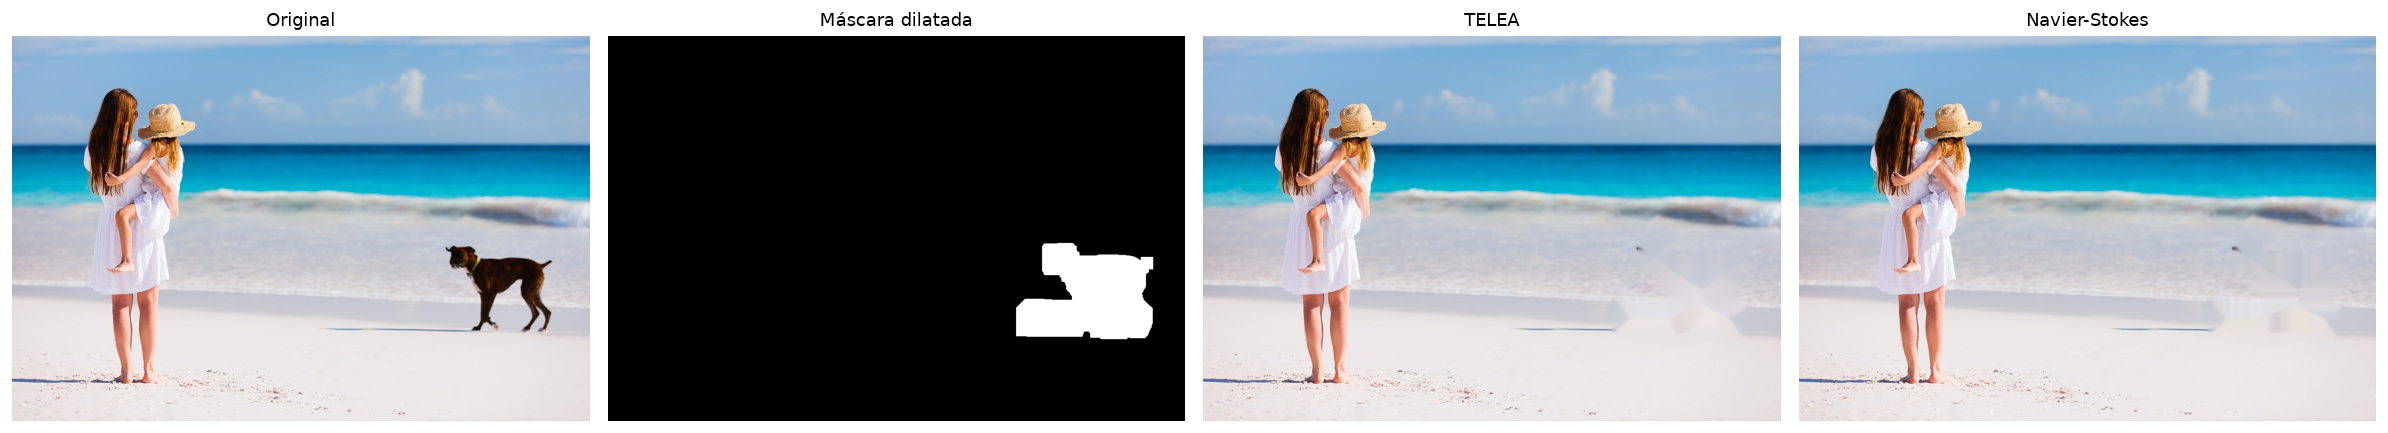

In [ ]:
# a máscara do GrabCut é "justa" demais: dilatamos um pouco para cobrir sombra e anti-aliasing das bordas
nucleo = np.ones((4, 4), np.uint8)
mascara_remocao_cachorro = cv2.dilate(mask_cachorro * 255, nucleo, iterations=7)

praia_sem_cachorro_telea = cv2.inpaint(imagem_base, mascara_remocao_cachorro, inpaintRadius=7, flags=cv2.INPAINT_TELEA)
praia_sem_cachorro_ns = cv2.inpaint(imagem_base, mascara_remocao_cachorro, inpaintRadius=7, flags=cv2.INPAINT_NS)

mostrar_lado_a_lado(
    [imagem_base, mascara_remocao_cachorro, praia_sem_cachorro_telea, praia_sem_cachorro_ns],
    ['Original', 'Máscara dilatada', 'TELEA', 'Navier-Stokes'],
    figsize=(20, 5),
    cmaps=[None, 'gray', None, None]
)

# vamos seguir com o resultado do TELEA no restante da aula
praia_sem_cachorro = praia_sem_cachorro_telea


### O efeito do raio de inpainting

O parâmetro `inpaintRadius` controla o quanto de vizinhança cada algoritmo considera. Valores pequenos tendem a deixar bordas "quadriculadas"; valores grandes suavizam mais, mas podem borrar texturas finas (como os grãos de areia).


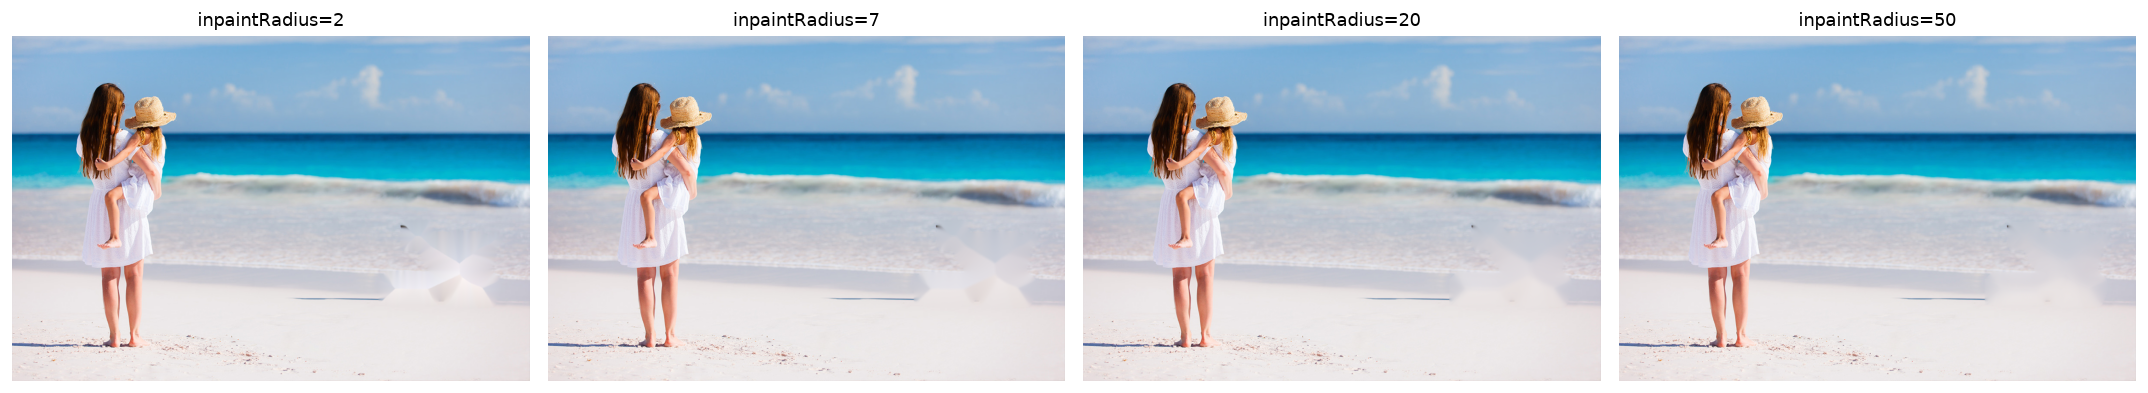

In [ ]:
raios = [2, 7, 20, 50]
resultados_raio = [
    cv2.inpaint(imagem_base, mascara_remocao_cachorro, inpaintRadius=r, flags=cv2.INPAINT_TELEA)
    for r in raios
]
mostrar_lado_a_lado(resultados_raio, [f'inpaintRadius={r}' for r in raios], figsize=(18, 5))


## 4. Remove people from image: onde o método clássico aperta o botão de pânico

Vamos repetir a receita da seção anterior, agora removendo a mãe e a criança de `praia_sem_cachorro`. A diferença é que a região delas atravessa **duas texturas muito diferentes**: o céu/mar ao fundo (com um horizonte bem definido) e a areia.

Isso expõe a limitação central do inpainting clássico: os algoritmos propagam informação *localmente*, ao longo da borda da máscara, sem entender que "aquilo é uma pessoa na frente de um horizonte reto". Quando a máscara cobre uma quebra de textura como o horizonte, o resultado tende a criar uma costura ou um "rasgo" visível — bem diferente do que um humano (ou um modelo generativo moderno) faria.


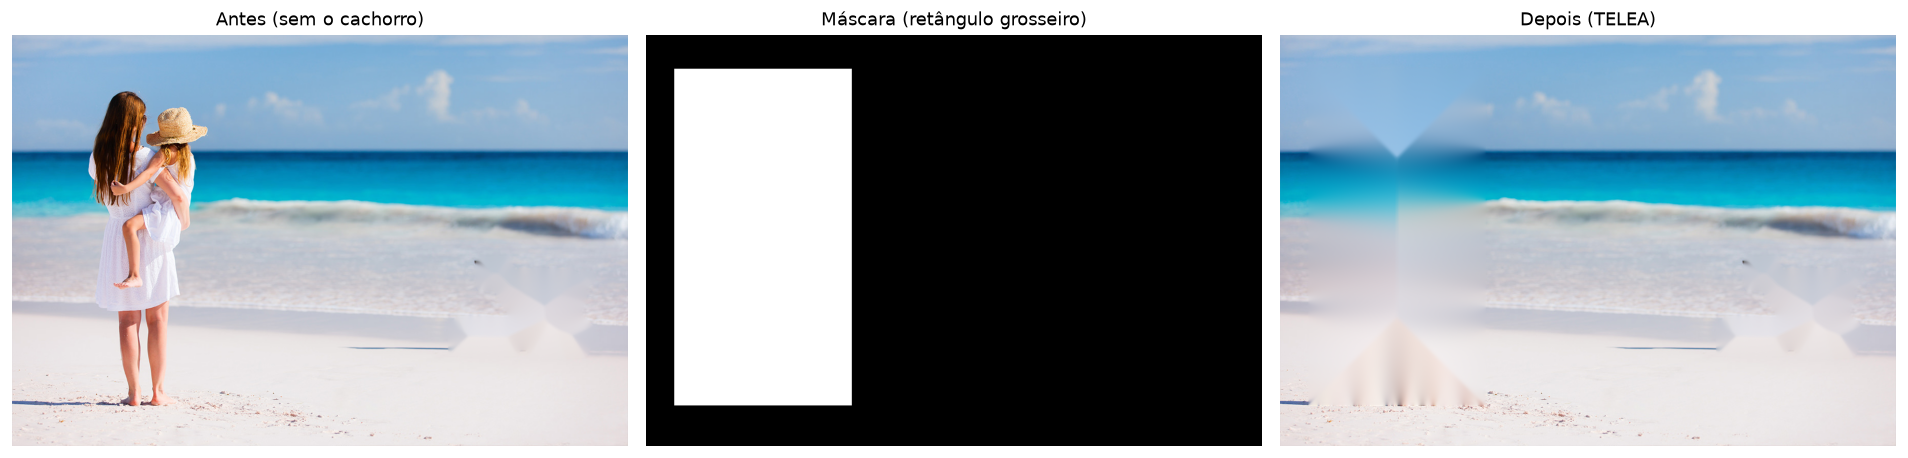

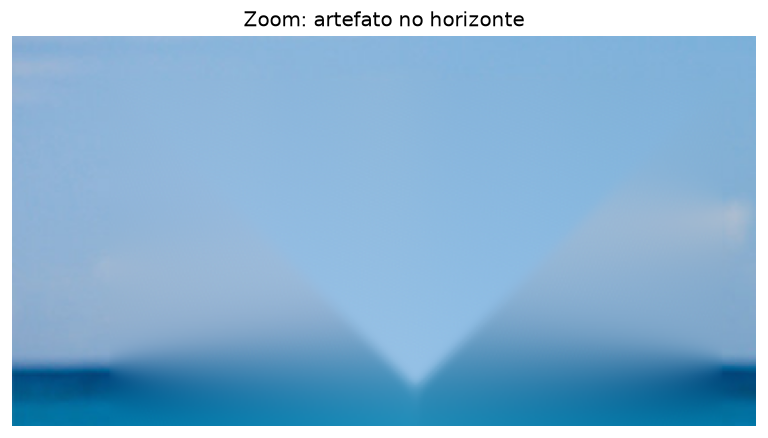

In [ ]:
mascara_pessoas = np.zeros(imagem_base.shape[:2], dtype=np.uint8)
x, y, w, h = rect_pessoas
cv2.rectangle(mascara_pessoas, (x, y), (x + w, y + h), 255, -1)

praia_sem_pessoas = cv2.inpaint(praia_sem_cachorro, mascara_pessoas, inpaintRadius=10, flags=cv2.INPAINT_TELEA)

mostrar_lado_a_lado(
    [praia_sem_cachorro, mascara_pessoas, praia_sem_pessoas],
    ['Antes (sem o cachorro)', 'Máscara (retângulo grosseiro)', 'Depois (TELEA)'],
    cmaps=[None, 'gray', None]
)

# zoom na "cicatriz" deixada pelo horizonte ao atravessar a máscara
zoom_cicatriz = praia_sem_pessoas[40:260, 0:420]
mostrar_imagem(zoom_cicatriz, 'Zoom: artefato no horizonte')


A "cicatriz" que aparece no zoom é bem visível: como a máscara atravessa o horizonte, o algoritmo tenta reconciliar duas regiões (o mar de um lado, o céu de outro) sem saber que deveria simplesmente continuar a linha reta do horizonte.

Duas melhorias simples ajudariam:
- uma **máscara mais precisa** (silhueta das pessoas, não um retângulo) reduziria a área "confusa";
- ainda assim, o algoritmo clássico não tem noção de "linha reta que deve continuar reta" — ele só sabe propagar cor e gradiente localmente, pixel a pixel.

É exatamente essa limitação que levou a área a adotar **modelos profundos de inpainting** (por exemplo, LaMa ou o inpainting do Stable Diffusion), que aprendem, a partir de milhões de imagens, estruturas como horizontes, linhas de perspectiva e texturas repetitivas — e conseguem "alucinar" um preenchimento plausível mesmo em situações como essa.

Antes de partir para os modelos profundos, vale aplicar a primeira melhoria da lista acima — ela é barata e resolve boa parte do problema.


### 4.1 A máscara importa mais que o algoritmo

O retângulo usado acima é *preguiçoso*: ele marca como "faltante" uma área enorme (355 × 655 pixels) que na verdade é, em sua maior parte, céu, mar e areia — pixels que **não precisavam ser reconstruídos**. Quanto maior a área marcada, mais o Telea/Navier-Stokes precisa "adivinhar" longe da borda, e é exatamente esse excesso de área que produz a mancha borrada no meio da máscara.

A correção é simples: em vez do retângulo, usamos a **silhueta** das pessoas — a mesma máscara do GrabCut que já calculamos na Seção 2 (`mask_pessoas`), limpa com abertura/fechamento morfológico (para remover os pequenos vazamentos que vimos naquela seção) e dilatada apenas o suficiente para cobrir a borda e a sombra. O resultado é uma máscara com uma fração da área do retângulo, que deixa o horizonte, o mar e a areia praticamente intocados.


Área do retângulo: 226976 px  |  Área da silhueta: 102630 px


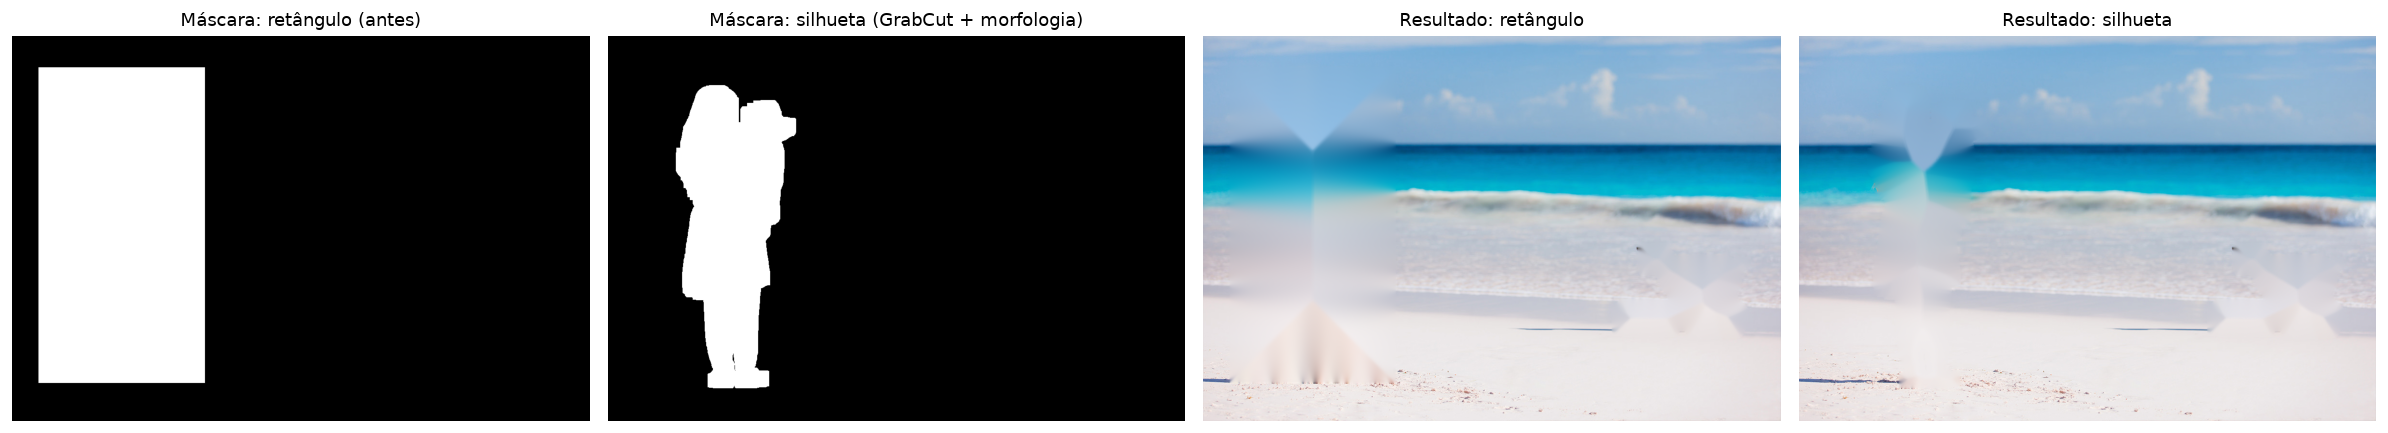

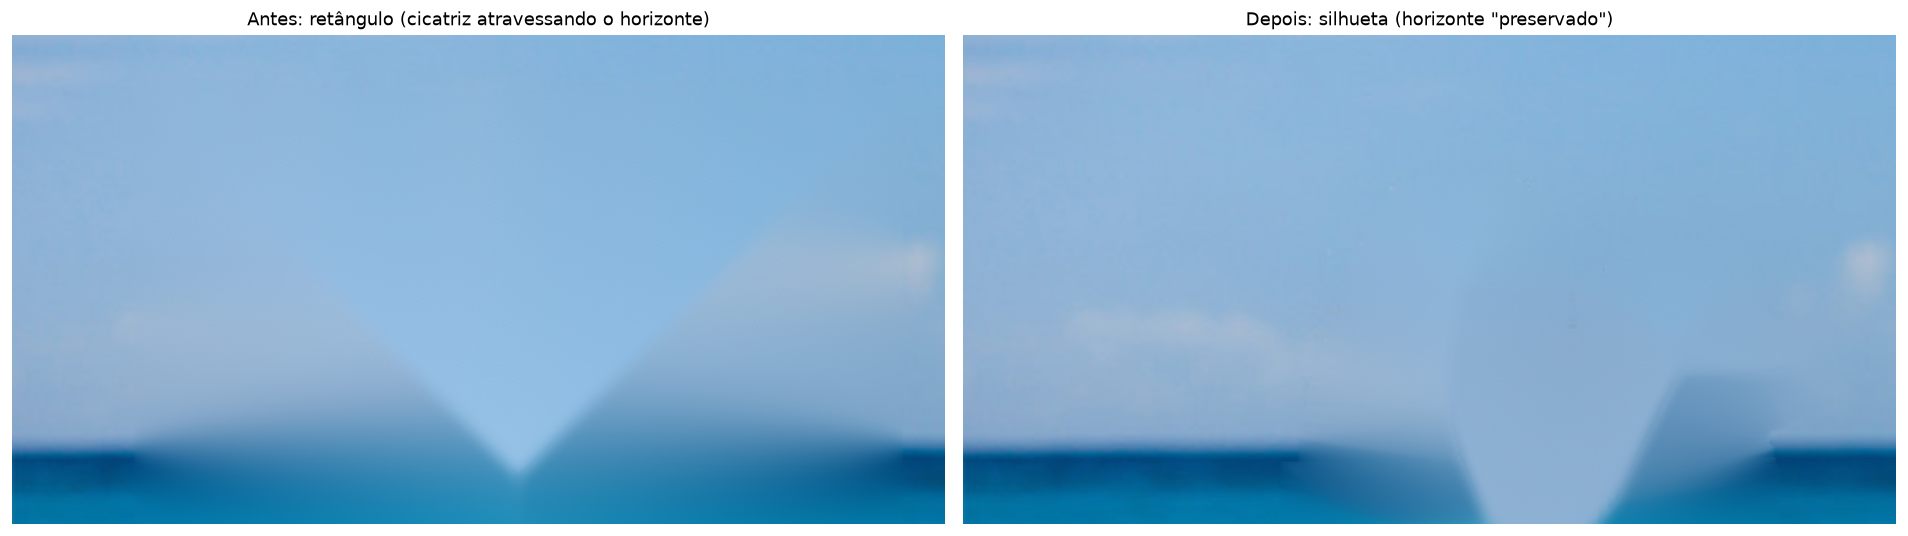

In [ ]:
# limpeza morfológica: abre (remove vazamentos pequenos) e fecha (preenche buraquinhos)
nucleo_pessoas = np.ones((8, 8), np.uint8)
mascara_pessoas_silhueta = cv2.morphologyEx(mask_pessoas * 255, cv2.MORPH_OPEN, nucleo_pessoas)
mascara_pessoas_silhueta = cv2.morphologyEx(mascara_pessoas_silhueta, cv2.MORPH_CLOSE, nucleo_pessoas)
mascara_pessoas_silhueta = cv2.dilate(mascara_pessoas_silhueta, np.ones((21, 21), np.uint8), iterations=1)

print('Área do retângulo:', (mascara_pessoas > 0).sum(), 'px  |  Área da silhueta:', (mascara_pessoas_silhueta > 0).sum(), 'px')

praia_sem_pessoas_silhueta = cv2.inpaint(praia_sem_cachorro, mascara_pessoas_silhueta, inpaintRadius=10, flags=cv2.INPAINT_TELEA)

mostrar_lado_a_lado(
    [mascara_pessoas, mascara_pessoas_silhueta, praia_sem_pessoas, praia_sem_pessoas_silhueta],
    ['Máscara: retângulo (antes)', 'Máscara: silhueta (GrabCut + morfologia)', 'Resultado: retângulo', 'Resultado: silhueta'],
    figsize=(20, 5),
    cmaps=['gray', 'gray', None, None]
)

# mesmo zoom da célula anterior, agora sobre o resultado com a silhueta
zoom_cicatriz_silhueta = praia_sem_pessoas_silhueta[40:260, 0:420]
mostrar_lado_a_lado(
    [zoom_cicatriz, zoom_cicatriz_silhueta],
    ['Antes: retângulo (cicatriz atravessando o horizonte)', 'Depois: silhueta (horizonte "preservado")']
)


O horizonte agora atravessa a cena quase sem interrupção — a máscara não cobre mais o céu e o mar que estavam ao redor das pessoas, então o Telea não precisa mais reconciliar duas texturas diferentes fora da região onde a pessoa realmente estava. Ainda sobra um leve borrão exatamente onde o corpo estava (o algoritmo continua sem "textura" real para colocar ali), mas o resultado já é muito mais aceitável do que com o retângulo — e sem precisar trocar de algoritmo, só de máscara.


## 5. Add people on image: reinserindo o cachorro em outro lugar

Vamos fechar o ciclo: extrair o recorte do cachorro (usando `mask_cachorro`, calculada na Seção 2) e colá-lo em outro ponto de `praia_sem_cachorro`.

### Duas formas de "colar" um recorte

**1. Alpha blending (o que já vimos):**

$$
I_{\text{final}}(x,y) = \alpha(x,y) \cdot I_{\text{objeto}}(x,y) + (1 - \alpha(x,y)) \cdot I_{\text{fundo}}(x,y)
$$

Se $\alpha$ for uma máscara binária "dura", a borda do recorte costuma ficar visível (um contorno serrilhado ou uma leve "caixa"). Suavizar $\alpha$ com um blur (**feathering**) já ajuda bastante — vamos comparar os dois casos lado a lado.

**2. Composição por gradiente (Poisson blending):** em vez de copiar valores de pixel, copiamos o **gradiente** do recorte e resolvemos uma equação de Poisson para reconstruir os valores de intensidade que melhor respeitam esse gradiente *e* concordam com o fundo na borda:

$$
\min_{J} \sum_{(x,y) \in \Omega} \|\nabla J(x,y) - \nabla I_{\text{objeto}}(x,y)\|^2 \quad \text{sujeito a} \quad J = I_{\text{fundo}} \text{ na borda de } \Omega
$$

Essa é a ideia por trás do `cv2.seamlessClone` (Poisson Image Editing, Pérez et al., 2003) — o mesmo princípio usado no "clone stamp com mistura" de editores profissionais.

> **Nota da bancada de testes:** ao preparar esta aula, `cv2.seamlessClone` produziu um resultado incorreto na versão do OpenCV instalada neste projeto (um recorte colado virou uma mancha sem nenhuma cor do objeto original — um bug conhecido em builds recentes/pré-lançamento do OpenCV 5). Por isso, vamos implementar e comparar visualmente **alpha blending com feathering**, que funciona de forma confiável aqui, e discutir o Poisson blending de forma conceitual.


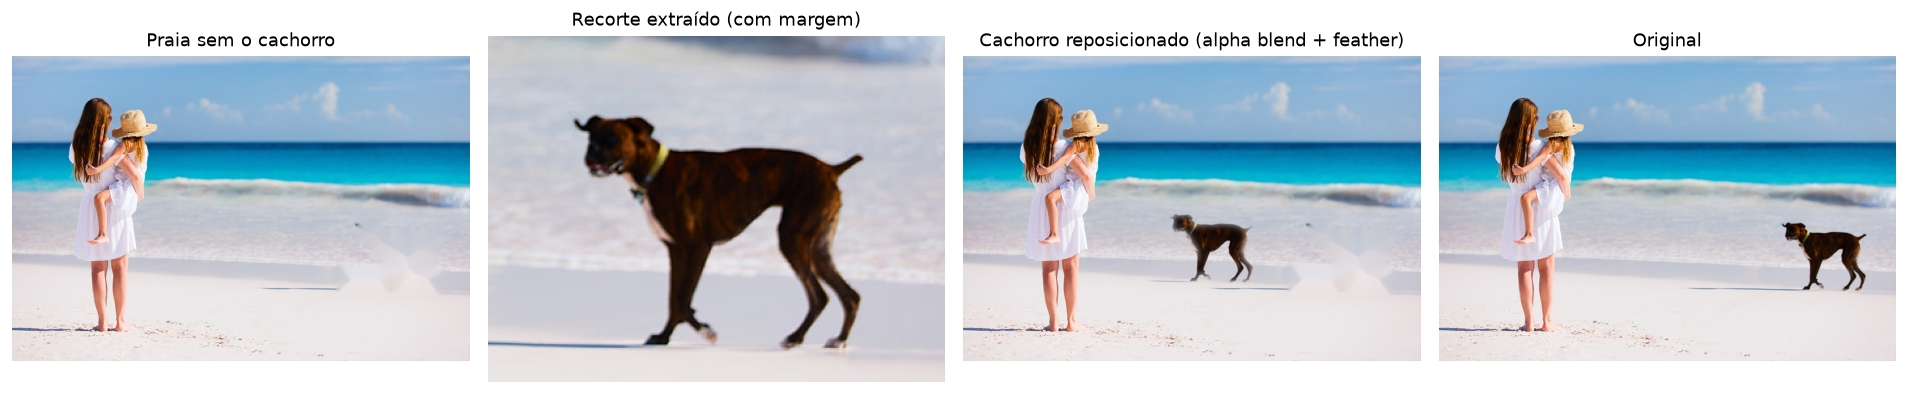

In [ ]:
x, y, w, h = rect_cachorro
margem = 20
x0, y0 = max(x - margem, 0), max(y - margem, 0)
x1, y1 = min(x + w + margem, imagem_base.shape[1]), min(y + h + margem, imagem_base.shape[0])

recorte_cachorro = imagem_base[y0:y1, x0:x1].copy()
mascara_recorte = (mask_cachorro[y0:y1, x0:x1] * 255).astype(np.uint8)

altura_recorte, largura_recorte = recorte_cachorro.shape[:2]
novo_centro = (650, 485)
cx0 = novo_centro[0] - largura_recorte // 2
cy0 = novo_centro[1] - altura_recorte // 2

alpha = mascara_com_feather(mascara_recorte, sigma=9)

praia_com_cachorro_reposicionado = praia_sem_cachorro.copy()
regiao_destino = praia_com_cachorro_reposicionado[cy0:cy0 + altura_recorte, cx0:cx0 + largura_recorte].astype(np.float32)
mistura = alpha * recorte_cachorro.astype(np.float32) + (1 - alpha) * regiao_destino
praia_com_cachorro_reposicionado[cy0:cy0 + altura_recorte, cx0:cx0 + largura_recorte] = np.clip(mistura, 0, 255).astype(np.uint8)

mostrar_lado_a_lado(
    [imagem_base, praia_com_cachorro_reposicionado ],
    ['Original', 'Cachorro reposicionado (alpha blend + feather)']
)


### O papel do feathering

Para ver por que suavizar a máscara importa, vamos repetir a composição sem feather (máscara binária "dura") e comparar lado a lado, com um zoom na borda do recorte.


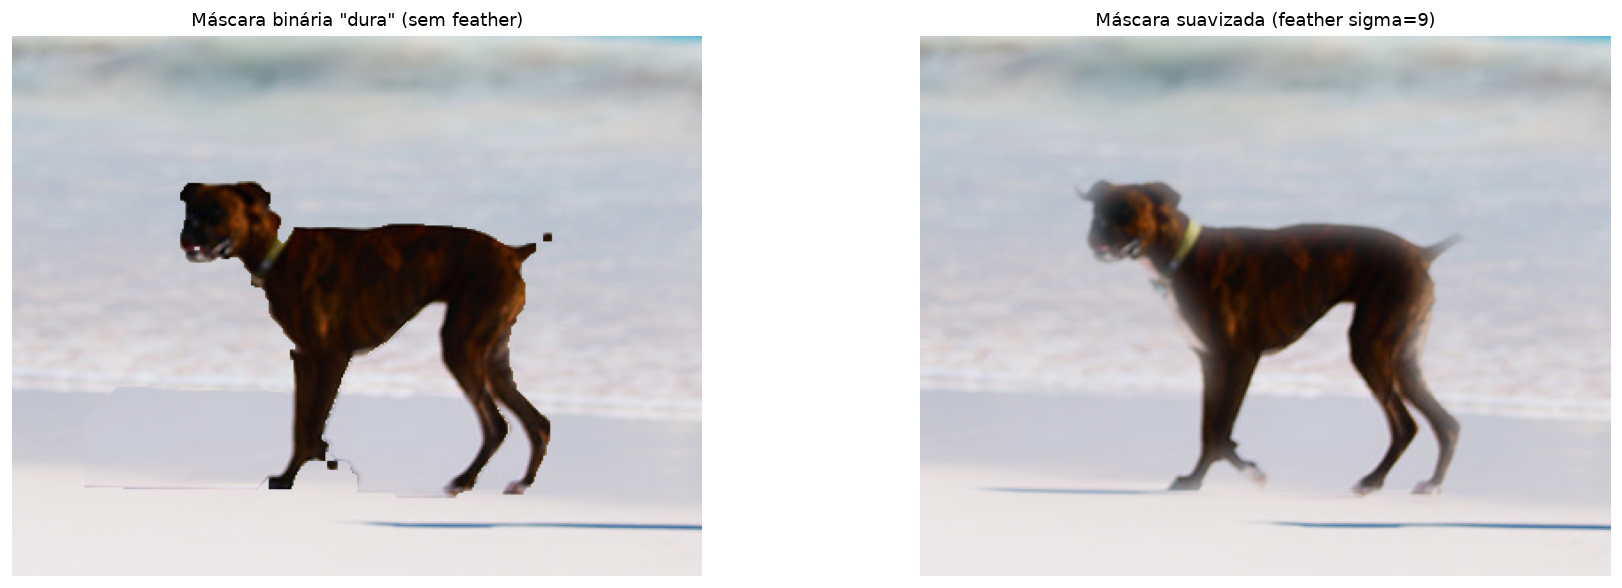

In [ ]:
alpha_duro = (mascara_recorte.astype(np.float32) / 255.0)[:, :, None]

praia_sem_feather = praia_sem_cachorro.copy()
regiao_destino2 = praia_sem_feather[cy0:cy0 + altura_recorte, cx0:cx0 + largura_recorte].astype(np.float32)
mistura_dura = alpha_duro * recorte_cachorro.astype(np.float32) + (1 - alpha_duro) * regiao_destino2
praia_sem_feather[cy0:cy0 + altura_recorte, cx0:cx0 + largura_recorte] = np.clip(mistura_dura, 0, 255).astype(np.uint8)

fatia_y = slice(max(cy0 - 20, 0), cy0 + altura_recorte + 20)
fatia_x = slice(max(cx0 - 20, 0), cx0 + largura_recorte + 20)

mostrar_lado_a_lado(
    [praia_sem_feather[fatia_y, fatia_x], praia_com_cachorro_reposicionado[fatia_y, fatia_x]],
    ['Máscara binária "dura" (sem feather)', 'Máscara suavizada (feather sigma=9)']
)


## 6. Discussão: do clássico aos modelos generativos

| Tarefa | Abordagem clássica (a de hoje) | Abordagem com IA generativa/profunda |
|---|---|---|
| Segmentação | GrabCut (GMM + corte de grafo, precisa de um retângulo inicial) | Segment Anything (SAM), redes de segmentação semântica/instância — um clique, e o modelo entende "isso é um cachorro" |
| Preenchimento (inpainting) | Telea / Navier-Stokes (propagação local de cor e gradiente) | LaMa, Stable Diffusion inpainting — "alucinam" texturas e estruturas plausíveis, entendendo contexto global |
| Composição de objetos | Alpha blending + feathering, Poisson blending | Harmonização por difusão (ajusta luz, sombra e estilo automaticamente) |
| Custo computacional | Milissegundos, roda bem em CPU | Segundos a minutos, geralmente precisa de GPU |
| Previsibilidade | Alta (determinístico, fácil de depurar) | Mais variável (o modelo pode "inventar" detalhes) |

Repare que os métodos clássicos que implementamos hoje ainda são extremamente úteis: são rápidos, previsíveis, não exigem GPU nem internet, e continuam presentes dentro de pipelines modernos (por exemplo, para refinar a borda de uma máscara gerada por uma rede neural). Entender essa camada é o que permite **escolher a ferramenta certa** para cada situação e **depurar quando o modelo generativo "erra"**.

### Uma nota sobre responsabilidade

Remover ou inserir pessoas em fotografias reais levanta questões éticas relevantes: consentimento, desinformação (*deepfakes*), e a expectativa de autenticidade em fotos jornalísticas ou documentais. Ferramentas de edição responsáveis costumam:

- registrar metadados de edição (por exemplo, Content Credentials / C2PA);
- restringir a manipulação de rostos de terceiros sem consentimento;
- adicionar marcas d'água ou avisos quando o conteúdo é sintético.

Como praticantes de visão computacional, vale sempre perguntar: *quem está na imagem, e essa pessoa autorizou o uso e a edição?*


## 7. Exercícios para praticar

1. **Novo objeto:** repita a Seção 2 escolhendo você mesmo um novo retângulo (por exemplo, só a cabeça do cachorro, ou apenas a sombra dele) e observe como a máscara muda.
2. **Fundo customizado:** na Seção 2, troque o `fundo_branco`/`fundo_desfocado` por um degradê de cores (`np.linspace` + `np.meshgrid`) e recomponha a imagem.
3. **Raio e iterações:** repita a Seção 3 variando `inpaintRadius` (tente 1, 3, 15, 40) e o número de `iteracoes` do GrabCut em `segmentar_grabcut`. Em que ponto o resultado para de melhorar?
4. **Ir além da Seção 4.1:** troque o kernel de dilatação (`np.ones((21, 21))`) por valores menores e maiores e observe o efeito na borda; depois repita a mesma ideia (máscara pela silhueta, em vez de retângulo) usando a máscara do `rembg` (Seção 9.1) — ela é mais precisa que a do GrabCut, o resultado melhora ainda mais?
5. **Novo destino:** na Seção 5, escolha um novo `novo_centro` para o cachorro reposicionado (por exemplo, mais perto da água) e observe se a diferença de iluminação/sombra entre origem e destino fica mais ou menos perceptível.
6. **(Desafio) Pesquisa dirigida:** procure uma ferramenta online de "generative fill" ou "remoção de objetos" (por exemplo, Photoshop, Google Fotos, remove.bg) e teste-a na mesma imagem `beach.jpg`. Compare o resultado com o que produzimos aqui e escreva 3 frases sobre as diferenças que você percebeu.


## 8. Conclusão

Ao longo desta aula, resolvemos quatro tarefas em cima de uma única fotografia, sempre reaproveitando a máscara e os recortes calculados nas etapas anteriores:

- **Segmentação (GrabCut):** transformamos um retângulo grosseiro em uma máscara binária via minimização de energia (estatística de cor + corte de grafo) — e vimos, com o exemplo das pessoas, que essa estatística pode "vazar" quando as cores se parecem.
- **Inpainting (Telea / Navier-Stokes):** removemos o cachorro com sucesso, porque a região a preencher era simples (só uma textura, a areia); a remoção das pessoas expôs o limite desses algoritmos quando a máscara atravessa uma quebra de textura, como o horizonte.
- **Composição (alpha blending com feathering):** reinserimos o cachorro em outro lugar da cena e comprovamos, lado a lado, por que suavizar a borda da máscara é essencial para evitar costuras visíveis — e por que, na indústria, o próximo passo natural é a composição por gradiente (Poisson blending / `cv2.seamlessClone`).

O padrão comum a tudo isso: **(1)** definir uma região de interesse (retângulo, máscara ou silhueta), **(2)** resolver um problema de otimização sobre ela (corte de grafo, difusão de gradiente, mistura de gradiente) e **(3)** compor o resultado de volta na cena. Modelos generativos modernos (SAM, LaMa, modelos de difusão) seguem exatamente esse mesmo padrão conceitual — a diferença é que a "estatística de cor local" dá lugar a um modelo treinado em milhões de imagens, capaz de entender contexto, textura e estrutura muito além da vizinhança imediata de um pixel.

### Para continuar

- **Segmentação semântica e por instância** (U-Net, Mask R-CNN, Segment Anything): máscaras que entendem "o que" é o objeto, não só "que cor" ele tem.
- **Modelos de difusão para inpainting** (Stable Diffusion inpainting, DALL·E outpainting): preenchimento guiado por texto e por um entendimento global da cena.
- **Poisson Image Editing** (Pérez et al., 2003) e suas variantes: a base matemática por trás da composição "sem costura" usada em ferramentas profissionais.
- **Vídeo:** as mesmas ideias (segmentação, inpainting, composição), mas com a dimensão extra da consistência temporal entre quadros.


## 9. Bônus: as mesmas tarefas com bibliotecas prontas

Repare que os resultados clássicos que produzimos (GrabCut, Telea/Navier-Stokes) são didáticos, mas visivelmente imperfeitos: vazamentos na máscara, cicatrizes no horizonte, bordas que precisam de feathering manual. Isso é esperado — implementamos a matemática "na mão" para entender o que está por trás da mágica.

Na prática, ninguém reimplementa GrabCut ou Telea do zero em produção. Existem bibliotecas prontas, treinadas ou otimizadas especificamente para essas tarefas, que entregam resultados muito melhores com poucas linhas de código. Duas delas, que rodam bem em CPU e já estão instaladas neste projeto:

- **[`rembg`](https://github.com/danielgatis/rembg)**: usa uma rede neural pré-treinada (U²-Net) para *background removal*. É o mesmo tipo de modelo por trás do remove.bg.
- **[`scikit-image`](https://scikit-image.org/)** (`skimage.restoration.inpaint_biharmonic`): resolve o inpainting como uma equação biharmônica sobre a região faltante — uma formulação matemática mais sofisticada que o Telea/Navier-Stokes do OpenCV, e sem parâmetros de raio para ajustar manualmente.

> **Para o trabalho:** vocês devem usar bibliotecas prontas como estas (ou equivalentes, como `iopaint`/LaMa para inpainting, ou modelos de segmentação do `transformers`/SAM) em vez de reimplementar os algoritmos clássicos. O objetivo desta seção é mostrar o ponto de partida e o quanto a qualidade sobe ao trocar "matemática artesanal" por um modelo pronto.



### 9.1 Background removal com `rembg`

`rembg` carrega um modelo pré-treinado (por padrão, `u2net`) e devolve diretamente uma imagem RGBA, onde o canal alpha já é a máscara de segmentação — sem precisar de um retângulo inicial, sem GMM, sem corte de grafo manual.

Vamos comparar o resultado com a máscara do GrabCut, no mesmo recorte do cachorro (`recorte_cachorro`, calculado na Seção 5) e também na região das pessoas, onde o GrabCut "vazava".



  0%|                                               | 0.00/176M [00:00<?, ?B/s]

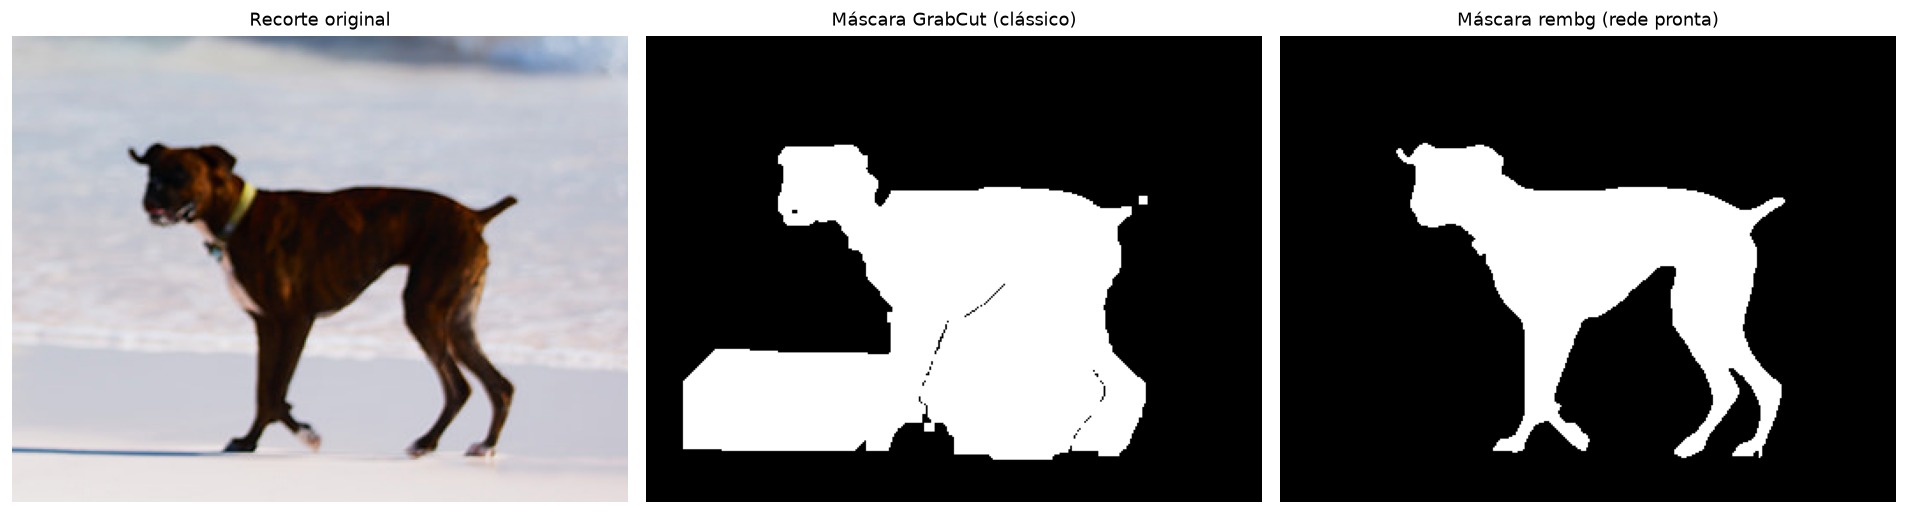

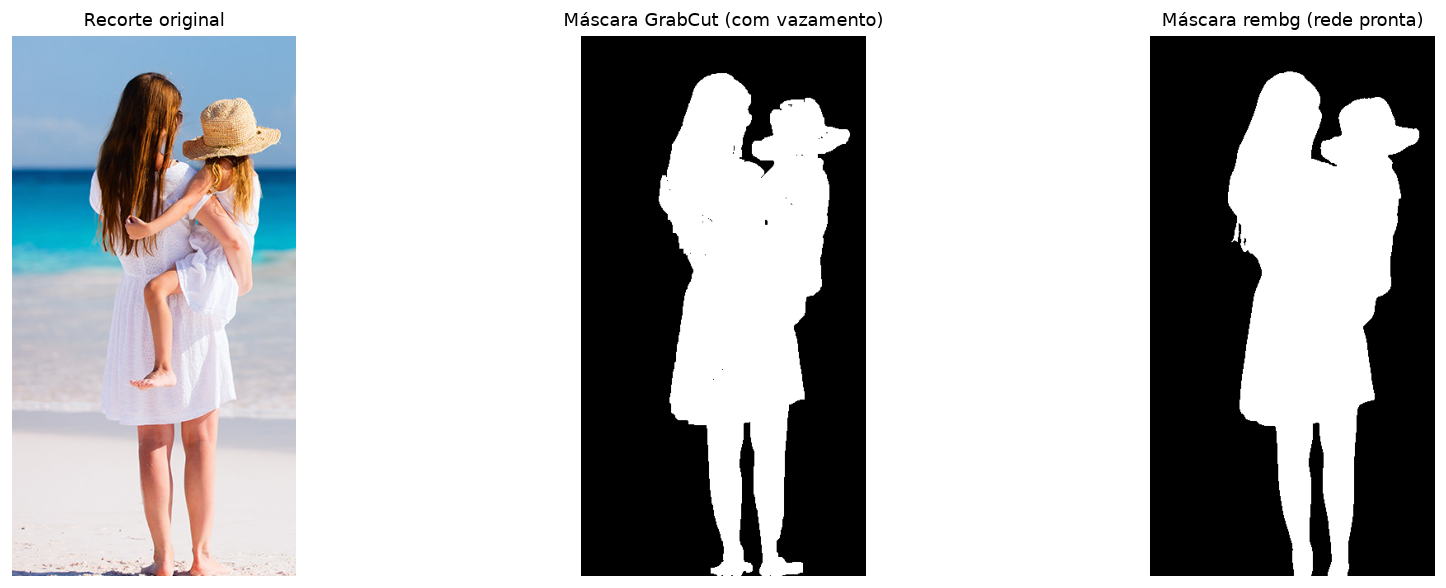

In [ ]:
from PIL import Image
from rembg import new_session, remove

sessao_rembg = new_session('u2net')


def mascara_rembg(imagem_rgb):
    """Roda o rembg (rede U²-Net) e devolve uma máscara binária (1 = objeto, 0 = fundo)."""
    resultado = remove(Image.fromarray(imagem_rgb), session=sessao_rembg)
    alpha = np.array(resultado)[:, :, 3]
    return (alpha > 127).astype(np.uint8)


# comparação no recorte do cachorro (recorte_cachorro vem da Seção 5)
mask_cachorro_rembg = mascara_rembg(recorte_cachorro)
mask_cachorro_grabcut_recorte = mask_cachorro[y0:y1, x0:x1]

mostrar_lado_a_lado(
    [recorte_cachorro, mask_cachorro_grabcut_recorte * 255, mask_cachorro_rembg * 255],
    ['Recorte original', 'Máscara GrabCut (clássico)', 'Máscara rembg (rede pronta)'],
    cmaps=[None, 'gray', 'gray']
)

# comparação na região das pessoas, onde o GrabCut "vazava" (rect_pessoas, Seção 2)
x, y, w, h = rect_pessoas
recorte_pessoas = imagem_base[y:y + h, x:x + w]
mask_pessoas_rembg = mascara_rembg(recorte_pessoas)
mask_pessoas_grabcut_recorte = mask_pessoas[y:y + h, x:x + w]

mostrar_lado_a_lado(
    [recorte_pessoas, mask_pessoas_grabcut_recorte * 255, mask_pessoas_rembg * 255],
    ['Recorte original', 'Máscara GrabCut (com vazamento)', 'Máscara rembg (rede pronta)'],
    cmaps=[None, 'gray', 'gray']
)



### 9.2 Content-aware fill com deep learning (LaMa e Stable Diffusion)

Diferente do `cv2.inpaint`, que resolve o preenchimento propagando textura a partir das bordas da máscara, modelos como **LaMa** e **Stable Diffusion** usam redes neurais treinadas para entender o conteúdo da imagem e gerar um preenchimento coerente com o resto da cena — sem depender de um `inpaintRadius` nem de heurísticas geométricas.

Vamos rodá-los sobre a máscara do cachorro (`mascara_remocao_cachorro`, Seção 3) e sobre a **máscara da silhueta** das pessoas (`mascara_pessoas_silhueta`, Seção 4.1). A mesma lição de que "a máscara importa mais que o algoritmo" vale para qualquer método de inpainting, clássico ou não.



In [3]:
import torch
from simple_lama_inpainting import SimpleLama

# --- LaMa ---
_simple_lama = SimpleLama(device=torch.device("cpu"))

def inpaint_lama(imagem_rgb, mascara_uint8):
    """Aplica inpainting com LaMa (deep learning) sobre a mesma máscara binária usada com cv2.inpaint."""
    imagem_pil = Image.fromarray(imagem_rgb)
    mascara_pil = Image.fromarray(mascara_uint8).convert('L')
    resultado = _simple_lama(imagem_pil, mascara_pil)
    return np.array(resultado)

In [ ]:
# import torch
# from diffusers import StableDiffusionInpaintPipeline

# # --- Stable Diffusion Inpainting ---
# _sd_pipe = StableDiffusionInpaintPipeline.from_pretrained(
#     "runwayml/stable-diffusion-inpainting",
#     torch_dtype=torch.float16,
# ).to("cuda")

# def inpaint_stable_diffusion(imagem_rgb, mascara_uint8, prompt="areia de praia, fotografia realista"):
#     """Aplica inpainting generativo com Stable Diffusion sobre a mesma máscara binária usada com cv2.inpaint."""
#     imagem_pil = Image.fromarray(imagem_rgb).convert('RGB')
#     mascara_pil = Image.fromarray(mascara_uint8).convert('L')
#     resultado = _sd_pipe(
#         prompt=prompt,
#         image=imagem_pil,
#         mask_image=mascara_pil,
#     ).images[0]
#     return np.array(resultado.resize(imagem_pil.size))


AttributeError: partially initialized module 'torch._dynamo' has no attribute 'decorators' (most likely due to a circular import)

In [6]:

# caso "fácil": remoção do cachorro (mesma máscara da Seção 3)
praia_sem_cachorro_lama = inpaint_lama(imagem_base, mascara_remocao_cachorro)
# praia_sem_cachorro_sd = inpaint_stable_diffusion(imagem_base, mascara_remocao_cachorro)

mostrar_lado_a_lado(
    [praia_sem_cachorro_telea, praia_sem_cachorro_ns, praia_sem_cachorro_lama],#, praia_sem_cachorro_sd],
    ['TELEA (OpenCV, clássico)', 'Navier-Stokes (OpenCV, clássico)', 'LaMa (deep learning)']# , 'Stable Diffusion (generativo)']
)

# # caso "difícil": remoção das pessoas, agora com a máscara da silhueta (Seção 4.1) em vez do retângulo
# praia_sem_pessoas_lama = inpaint_lama(praia_sem_cachorro, mascara_pessoas_silhueta)
# praia_sem_pessoas_sd = inpaint_stable_diffusion(praia_sem_cachorro, mascara_pessoas_silhueta)

# mostrar_lado_a_lado(
#     [praia_sem_pessoas, praia_sem_pessoas_silhueta, praia_sem_pessoas_lama, praia_sem_pessoas_sd],
#     ['Retângulo + TELEA (pior caso)', 'Silhueta + TELEA (clássico melhorado)', 'Silhueta + LaMa', 'Silhueta + Stable Diffusion']
# )

NameError: name 'imagem_base' is not defined

### 9.3 Expandindo o horizonte com outpainting

Até agora usamos inpainting para *remover* conteúdo de uma região já existente na imagem. O **outpainting** resolve o problema oposto: aumentar o canvas original e gerar conteúdo novo nas bordas, de forma coerente com a cena — por exemplo, estender o céu, o mar ou o horizonte de uma foto de praia.

A mecânica é parecida com a do inpainting generativo (Seção 9.2), com duas diferenças importantes:

1. **A máscara é invertida.** Em vez de marcar em branco a área que queremos apagar, marcamos em branco a área *nova* do canvas (onde não havia pixel nenhum) e em preto a imagem original, que deve ser preservada.
2. **O prompt carrega quase todo o peso do resultado.** Como não há textura vizinha imediata para "continuar" além da borda da imagem original, o modelo está essencialmente gerando conteúdo do zero guiado pela descrição — então vale a pena ser específico sobre o que deve aparecer na extensão (céu, nuvens, mar, areia etc.).

Vamos aplicar isso à imagem da praia, expandindo o horizonte para cima (mais céu) e para os lados, e comparar o resultado com a imagem original.

In [ ]:
import numpy as np
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageOps

_sd_pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16,
).to("cuda")


def expandir_horizonte(imagem_rgb, pixels_topo=0, pixels_baixo=0, pixels_esquerda=0, pixels_direita=0,
                        prompt="continuação natural da paisagem, céu e horizonte, fotografia realista"):
    """
    Aumenta o canvas da imagem nas direções indicadas e usa Stable Diffusion
    para preencher (outpainting) a área nova de forma coerente com a cena original.
    """
    imagem_pil = Image.fromarray(imagem_rgb).convert('RGB')
    largura, altura = imagem_pil.size

    nova_largura = largura + pixels_esquerda + pixels_direita
    nova_altura = altura + pixels_topo + pixels_baixo

    # canvas novo, com a imagem original colada na posição correta
    canvas = Image.new('RGB', (nova_largura, nova_altura))
    canvas.paste(imagem_pil, (pixels_esquerda, pixels_topo))

    # máscara: branco = área nova a ser preenchida, preto = imagem original (preservar)
    mascara = Image.new('L', (nova_largura, nova_altura), 255)
    mascara.paste(0, (pixels_esquerda, pixels_topo, pixels_esquerda + largura, pixels_topo + altura))

    resultado = _sd_pipe(
        prompt=prompt,
        image=canvas,
        mask_image=mascara,
        height=nova_altura - (nova_altura % 8),  # SD costuma exigir múltiplos de 8
        width=nova_largura - (nova_largura % 8),
    ).images[0]

    return np.array(resultado.resize((nova_largura, nova_altura)))


# exemplo: estender o horizonte da praia 300px pra cima (mais céu) e 200px pros lados
praia_horizonte_expandido = expandir_horizonte(
    imagem_base,
    pixels_topo=300,
    pixels_esquerda=200,
    pixels_direita=200,
    prompt="céu azul com nuvens, continuação da praia, horizonte do mar, fotografia realista"
)

mostrar_lado_a_lado(
    [imagem_base, praia_horizonte_expandido],
    ['Original', 'Horizonte expandido (outpainting)']
)